# Cải tiến mô hình và khuyến nghị AI04

UNETI15 · Năm cảm biến UCI Occupancy Detection

Mục tiêu gồm giảm mẫu có người bị nhận thành trống, giảm khuyến nghị sai theo chuỗi và giữ khả năng nhận ra phòng trống. Bản này so sánh 14 phương án, 6 chính sách, kiểm tra theo ngày và phân tích ca 07:36.

Validation đã được xem trong các lượt trước. Protocol, quy tắc Light guard và nguồn tham khảo được công khai. Notebook đọc các kết quả đã chạy; RETRAIN=True thực thi lại toàn bộ phần học và kiểm tra lồng nhau.

Quy trình chọn Logistic đa thức ban đầu gồm 16 cấu hình, được giải thích tại PHUONG_PHAP_MO_HINH.md và src/Train.ipynb. Phần 14 phương án dưới đây là nghiên cứu mở rộng với phép chia bổ sung.


In [ ]:
from pathlib import Path
import os, sys, json
ROOT = Path.cwd()
if ROOT.name == "src":
    ROOT = ROOT.parent
if not (ROOT / "src/improvement.py").exists():
    raise RuntimeError("Mở notebook trong thư mục dự án có README.")
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src import improvement as study
from src.revised_model import read_sensors
R = ROOT / "results/cai_tien"
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11})
RETRAIN = False
print("Thư mục", ROOT.name)
print("Học lại", RETRAIN)

Thư mục UNETI15_NguoiHaTayChat_AI04
Học lại False


## Quy định thực nghiệm

Các mô hình chỉ đọc năm cảm biến hoặc tập con/biến đổi nhân quả của chúng. Thời gian được dùng để chia chuỗi. Ngưỡng thay đổi ánh sáng được học lại trong phần học từng fold.

In [2]:
protocol = json.loads(study.PROTOCOL.read_text())
for name in ("data", "selection", "splits", "policy", "policy_selection", "validation"):
    print(name, "—", protocol[name], "\n")

data — Huấn luyện và chọn mọi giá trị bằng datatraining.txt. Không thêm dữ liệu bên ngoài, không dùng datatest2, ID hoặc lịch làm biến dự đoán. 

selection — Ưu tiên các ứng viên có FER<=1% và FPR<=8% trong cả grouped và forward. Xếp theo min Macro-F1 hai phép chia, rồi trung bình Macro-F1, số mô hình thành phần, thứ tự khai báo, ngưỡng. Nếu không đạt lọc thì tối thiểu trung bình (5FN+FP)/n, sau đó cùng quy tắc. Đây là giả định thiết kế. 

splits — 3 SGKF khối 2 giờ, seed2026, purge 10 phút sát mọi mẫu giữ lại để tránh bộ nhớ 10 mẫu đi qua biên. Forward theo ngày, học trước đầu ngày ít nhất 2 giờ, giữ cả ngày toàn trống. Inner selection lặp trong mỗi outer day khi đủ điều kiện, nếu thiếu forward evidence thì dùng cấu hình UNETI15 cố định. 

policy — So sánh giữ p<0.2 trong 3 mẫu, gap120; tăng 5 và 10 mẫu; learned light delta guard; guard cộng cooldown3; guard mức sáng tuyệt đối. Delta guard học phân vị99 của mức tăng Light dương ở hai mẫu train đều trống và liên tiếp 0<dt<=120 giây. Ve

In [3]:
train = read_sensors(ROOT / "data/AI04/datatraining.txt")
counts = train.Occupancy.value_counts().sort_index()
display(pd.DataFrame({"Số mẫu": counts, "Tỷ lệ (%)": counts / len(train) * 100}))
print("Ngưỡng guard học từ train", study.fit_guard(train))

Ngưỡng guard học từ train {'delta_lux': 165.87500000000045, 'positive_empty_steps': 471, 'dark_lux': 31.0}


,Số mẫu,Tỷ lệ (%)
Occupancy,,
0,6414,78.767039
1,1729,21.232961


## Huấn luyện và kiểm tra lồng nhau

12 mô hình được fit trong từng phần học. Hai công thức OR kết hợp điểm theo các mốc đã khai báo. Bốn ngưỡng dùng chung và hai mốc lịch sử tạo 58 lựa chọn phân lớp. Chọn theo min Macro-F1 của hai cách chia, kèm giới hạn FER/FPR. Toàn bộ bước chọn chạy lại trong mỗi ngày ngoài. Lệnh train độc lập với việc đọc validation.

In [4]:
if RETRAIN:
    from threadpoolctl import threadpool_limits
    with threadpool_limits(limits=1):
        study.train()
lock = json.loads((R / "selection_locked.json").read_text())
assert lock["train_sha256"] == study.file_hash(ROOT / "data/AI04/datatraining.txt")
assert lock["protocol_sha256"] == study.file_hash(study.PROTOCOL)
print(json.dumps(lock, ensure_ascii=False, indent=2))
display(pd.read_csv(R / "splits.csv"))

{
  "model": "temporal",
  "threshold": 0.65,
  "fallback": false,
  "action": {
    "policy": "three",
    "fallback": false
  },
  "original_action": {
    "policy": "delta",
    "fallback": false
  },
  "train_sha256": "b2c4d0ce2b9e4e453c476f7125ef31aeec2d1f5c7f5572d0e80de3df6521ab56",
  "protocol_sha256": "3293da5965854b5742d884945c3d44d39e6d89e4eb3d4b313cc34943f1290534",
  "source_sha256": "bf0d8269845512863a1dc4d1928f768eaaa66a002dc7300a428dd3aafc1d7b12",
  "guard": {
    "delta_lux": 165.87500000000045,
    "positive_empty_steps": 471,
    "dark_lux": 31.0
  },
  "validation_history": "previously inspected development set"
}


,scheme,fold,learning,held,occupied,delta_lux,positive_empty_steps,dark_lux
0,grouped,1,5072,2756,619,153.706667,303,31.0
1,grouped,2,5112,2774,645,232.850000,298,31.0
2,grouped,3,5230,2613,465,198.386667,293,209.5
3,forward,2015-02-06,1689,1440,586,62.300000,35,213.0
4,forward,2015-02-07,3129,1440,0,159.173333,55,213.0
5,forward,2015-02-08,4569,1440,0,142.313333,264,213.0
6,forward,2015-02-09,6009,1440,534,144.405000,467,213.0
7,forward,2015-02-10,7449,574,54,154.077500,470,31.0


In [5]:
grid = pd.read_csv(R / "model_grid.csv")
columns = ["name", "threshold", "grouped_FN", "grouped_FP", "forward_FN", "forward_FP", "worst_f1", "eligible"]
display(grid.sort_values("worst_f1", ascending=False)[columns].head(16))
display(pd.read_csv(R / "policy_grid_goc.csv"))
display(pd.read_csv(R / "nested_summary.csv"))

,name,threshold,grouped_FN,grouped_FP,forward_FN,forward_FP,worst_f1,eligible
44,HGB đơn điệu Light+CO₂,0.800,16,94,12,15,0.980132,False
47,Logistic với tín hiệu quá khứ,0.625,17,102,4,64,0.978537,True
48,Logistic với tín hiệu quá khứ,0.650,17,102,4,53,0.978537,True
35,HGB 5 cảm biến,0.650,25,95,25,55,0.978290,False
43,HGB đơn điệu Light+CO₂,0.650,10,114,4,23,0.977721,True
27,Random Forest 5 cảm biến,0.650,55,81,53,47,0.973809,False
52,OR Logistic đa thức và 2 cảm biến,0.650,18,126,2,107,0.972447,False
57,OR Logistic đa thức và quá khứ,0.800,45,113,17,42,0.971404,False
12,Logistic Light+CO₂,0.800,48,116,35,68,0.970318,False
56,OR Logistic đa thức và quá khứ,0.650,14,133,2,118,0.969769,True


,policy,order,grouped_unsafe,grouped_rate,grouped_coverage,forward_unsafe,forward_rate,forward_coverage,worst_rate,min_coverage
0,three,0,49,0.028340,0.936857,0,0.0,0.928488,0.028340,0.928488
1,five,1,47,0.027183,0.917524,0,0.0,0.921705,0.027183,0.917524
2,ten,2,44,0.025448,0.869816,0,0.0,0.906395,0.025448,0.869816
3,delta,3,47,0.027183,0.936701,0,0.0,0.928101,0.027183,0.928101
4,cooldown,4,47,0.027183,0.936389,0,0.0,0.928101,0.027183,0.928101
5,dark,5,0,0.000000,0.859838,0,0.0,0.928295,0.000000,0.859838


,variant,n,TN,FP,FN,TP,FER,FPR,Macro_F1,unsafe,good,coverage
0,btc,6334,5107,53,33,1141,0.028109,0.010271,0.977666,0,4906,0.950775
1,goc,6334,4947,213,2,1172,0.001704,0.041279,0.947357,0,4791,0.928488
2,goc_delta,6334,4947,213,2,1172,0.001704,0.041279,0.947357,0,4789,0.928101
3,selected,6334,4921,239,17,1157,0.014480,0.046318,0.937519,0,4862,0.942248


## Mô hình OR và bộ chặn ánh sáng

OR2 dự đoán có người khi Logistic đa thức ≥0,50 hoặc Logistic Light+CO₂ ≥0,70. OR quá khứ thay thành phần thứ hai bằng Logistic có độ dốc CO₂ và mức tăng/giảm ánh sáng, mốc 0,625. Điểm kết hợp là chỉ số quyết định. Tầng khuyến nghị tích lũy khi điểm <0,20 và hủy chuỗi khi ánh sáng tăng vượt phân vị99% học trên train.

Lựa chọn demo OR2 có sự tham gia của người đánh giá từ bằng chứng phát triển. Kết quả chọn theo Macro-F1 trên train được giữ nguyên ở lock để kiểm tra độc lập.

In [6]:
deployment = json.loads((ROOT / "research/deployment_choice.json").read_text())
print(json.dumps(deployment, ensure_ascii=False, indent=2))

{
  "default_mode": "or2",
  "status": "Lựa chọn thực hành từ bằng chứng phát triển đã được quan sát, cần kiểm chứng ở phòng mới.",
  "rationale": "Hai Logistic cố định bổ sung tín hiệu cho nhau, giảm FN từ2 xuống1 với FP55; delta guard giảm unsafe1 xuống0 và giữ1631 khuyến nghị đúng trên validation. Grouped và forward OOF của OR2+delta đều có0 unsafe, coverage trên90%.",
  "contrast": {
    "train_macro_f1_selector": "temporal threshold0.65",
    "validation_model_fn": 4,
    "validation_unsafe": 0,
    "temporal_or_mode": "ort",
    "temporal_or_validation_fn": 0,
    "temporal_or_correct_recommendations": 1624
  },
  "history": "OR, Light guard và lỗi07:36 đã được xem trong các lượt nghiên cứu trước. Đây không phải kết quả test độc lập.",
  "reference": "selection_locked.json giữ riêng kết quả thuật toán chọn theo min Macro-F1. Quyết định demo không thay đổi giá trị lock đó."
}


## Đo trên validation đã quan sát

Bảng đầy đủ công khai mọi mô hình và chính sách, gồm cả kết quả kém. Các ngưỡng không được dò trong ô đánh giá này.

In [7]:
if RETRAIN:
    study.evaluate()
validation = read_sensors(ROOT / "data/AI04/datatest.txt")
all_results = pd.read_csv(R / "validation_all_development.csv")
base = all_results[all_results.policy == "three"]
display(base[["name", "threshold", "Macro_F1", "FN", "FP", "unsafe", "good"]])
selected = all_results[((all_results.model.isin(["btc", "goc"])) & (all_results.policy == "three")) | ((all_results.model.isin(["goc", "or2", "ort"])) & (all_results.policy == "delta"))]
display(selected[["name", "policy", "Macro_F1", "FN", "FP", "unsafe", "good", "coverage", "detected_episodes", "empty_episodes"]])

,name,threshold,Macro_F1,FN,FP,unsafe,good
0,BTC Logistic 5 cảm biến,0.50,0.975547,7,54,1,1633
6,UNETI15 Logistic đa thức,0.50,0.977178,2,55,1,1631
12,Logistic Light+CO₂,0.70,0.976773,3,55,1,1621
18,LDA Light+CO₂,0.50,0.976782,2,56,1,1631
24,QDA Light+CO₂,0.50,0.976773,3,55,1,1631
30,SVM RBF Light+CO₂,0.50,0.970436,5,69,2,1593
36,Random Forest 5 cảm biến,0.50,0.948736,74,52,1,1612
42,Extra Trees 5 cảm biến,0.50,0.977187,1,56,1,1612
48,HGB 5 cảm biến,0.50,0.945506,77,57,8,1626
54,HGB Light+CO₂,0.50,0.975181,4,58,1,1626


,name,policy,Macro_F1,FN,FP,unsafe,good,coverage,detected_episodes,empty_episodes
0,BTC Logistic 5 cảm biến,three,0.975547,7,54,1,1633,0.964560,3,13
6,UNETI15 Logistic đa thức,three,0.977178,2,55,1,1631,0.963379,3,13
9,UNETI15 Logistic đa thức,delta,0.977178,2,55,0,1631,0.963379,3,13
75,OR Logistic đa thức và 2 cảm biến,delta,0.977583,1,55,0,1631,0.963379,3,13
81,OR Logistic đa thức và quá khứ,delta,0.977987,0,55,0,1624,0.959244,3,13


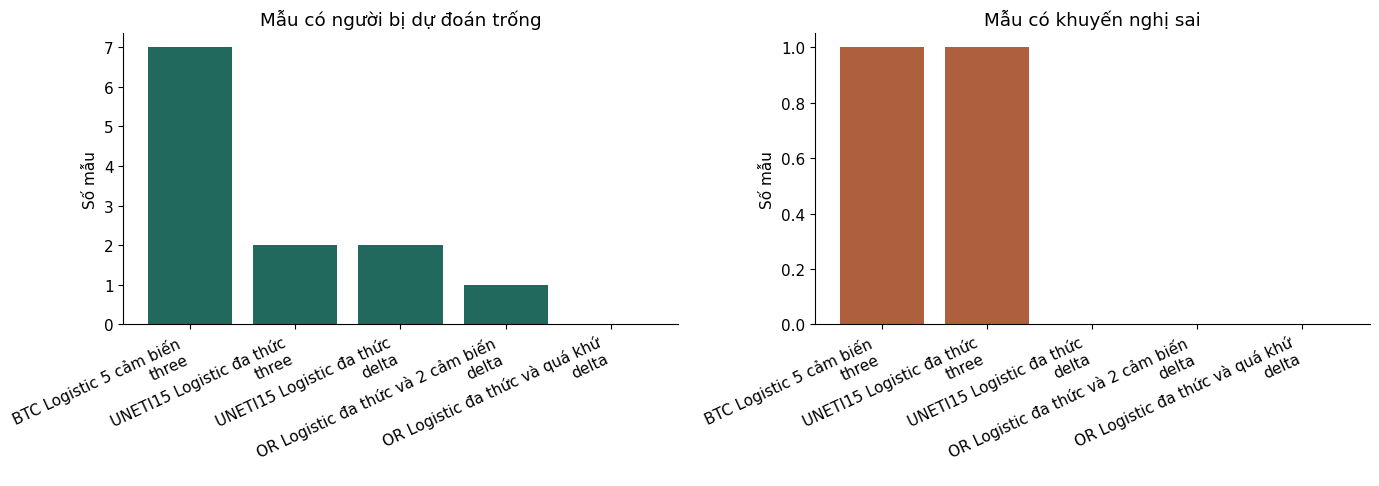

In [8]:
shown = selected.copy()
labels = [a + "\n" + b for a,b in zip(shown.name, shown.policy)]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(np.arange(len(shown)), shown.FN, color="#22695D")
axes[1].bar(np.arange(len(shown)), shown.unsafe, color="#AE5F3E")
for ax, title in zip(axes, ["Mẫu có người bị dự đoán trống", "Mẫu có khuyến nghị sai"]):
    ax.set_xticks(np.arange(len(shown)), labels, rotation=25, ha="right")
    ax.set_title(title)
    ax.set_ylabel("Số mẫu")
    ax.set_ylim(bottom=0)
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## Ca người vừa vào phòng

Phải nạp cả lịch sử trước07:36 để quan sát bộ đếm812. Guard học mốc165,875 lux từ train. Đến thời điểm lỗi, ánh sáng tăng217,2 lux nên bộ đếm bị hủy.

In [9]:
from backend.predictor import predict_sequence
prefix = validation[validation.date <= "2015-02-03 07:36:00"]
records = []
for mode in ["goc", "guard", "or2", "ort"]:
    record = predict_sequence(prefix, mode)[-1]
    records.append({"mode": mode, **record})
display(pd.DataFrame(records)[["mode", "score", "prediction", "streak", "recommend", "reason"]])
assert records[0]["streak"] == 812 and records[0]["recommend"]
assert records[2]["streak"] == 0 and not records[2]["recommend"]

,mode,score,prediction,streak,recommend,reason
0,goc,0.167617,0,812,True,Đủ ba mẫu điểm thấp. Đề xuất kiểm tra trực tiế...
1,guard,0.167617,0,0,False,"Ánh sáng tăng 217.20 lux, vượt mốc học từ trai..."
2,or2,0.167617,0,0,False,"Ánh sáng tăng 217.20 lux, vượt mốc học từ trai..."
3,ort,0.630490,1,0,False,"Ánh sáng tăng 217.20 lux, vượt mốc học từ trai..."


In [10]:
comparison = all_results[all_results.model == "goc"]
display(comparison[["policy", "unsafe", "good", "coverage", "detected_episodes", "median_delay_samples"]])
print("Tăng 5 hoặc10 mẫu chờ vẫn còn lỗi. Mức bao phủ cần đọc cùng số đợt được nhận ra.")
display(pd.read_csv(R / "diagnostic_low_thresholds.csv"))

Tăng 5 hoặc10 mẫu chờ vẫn còn lỗi. Mức bao phủ cần đọc cùng số đợt được nhận ra.


,policy,unsafe,good,coverage,detected_episodes,median_delay_samples
6,three,1,1631,0.963379,3,2.0
7,five,1,1625,0.959835,3,4.0
8,ten,1,1610,0.950975,3,9.0
9,delta,0,1631,0.963379,3,2.0
10,cooldown,0,1631,0.963379,3,2.0
11,dark,0,1611,0.951565,2,2.0


,scheme,low,unsafe,good,coverage,unsafe_rate,empty_episodes,detected_episodes,median_delay_samples
0,grouped,0.025,0,5777,0.900686,NaN,NaN,NaN,NaN
1,grouped,0.050,0,5867,0.914718,NaN,NaN,NaN,NaN
2,grouped,0.100,36,5944,0.926723,NaN,NaN,NaN,NaN
3,grouped,0.150,44,5970,0.930776,NaN,NaN,NaN,NaN
4,grouped,0.200,49,6009,0.936857,NaN,NaN,NaN,NaN
5,forward,0.025,0,3733,0.723450,NaN,NaN,NaN,NaN
6,forward,0.050,0,4588,0.889147,NaN,NaN,NaN,NaN
7,forward,0.100,0,4704,0.911628,NaN,NaN,NaN,NaN
8,forward,0.150,0,4757,0.921899,NaN,NaN,NaN,NaN
9,forward,0.200,0,4791,0.928488,NaN,NaN,NaN,NaN


## Kiểm tra kết quả chạy thật

Đối chiếu suy luận từ backend với bảng nghiên cứu. Các kiểm tra bổ sung về tương lai, dữ liệu lỗi và nhãn nằm trong tests/test_improvement.py.

In [11]:
detail = pd.read_csv(R / "validation_predictions.csv")
for mode, key, kind in [("guard", "goc", "delta"), ("or2", "or2", "delta"), ("ort", "ort", "delta")]:
    rows = predict_sequence(validation, mode)
    np.testing.assert_allclose([r["score"] for r in rows], detail[key + "_score"], rtol=0, atol=1e-10)
    assert [r["recommend"] for r in rows] == detail[key + "_" + kind + "_recommend"].tolist()
print("Ba phương án khớp toàn bộ2665 mẫu nghiên cứu.")

Ba phương án khớp toàn bộ2665 mẫu nghiên cứu.


## Cách diễn giải kết quả

OR2 + guard giảm FN2→1 và khuyến nghị sai1→0, giữ1631 khuyến nghị đúng. OR quá khứ + guard đạt0 FN,0 khuyến nghị sai và1624 khuyến nghị đúng. Ba trong13 đợt trống được phát hiện. Kết quả lồng nhau cho thấy quy trình tự chọn còn biến động qua ngày.

Tập mới và phòng mới cần được dùng để kiểm chứng khả năng tổng quát. Điện năng cần đo công suất, trạng thái bật/tắt và thời gian thiết bị hoạt động. Nguồn, đóng góp và lịch sử đã xem validation được ghi trong SOURCES.md và README.md.